In [ ]:
# this notebook should show the main steps to incorporate BASiL in a gammapy analysis
# and compute main auxiliary stuff
# maybe a separate notebook for 3D

# I can try doing a "BASiL" analysis by faking values and distribution of GAMMANNESS 
# using the DR1 data (from gammapy)

In [173]:
from gammapy.data import DataStore, EventList, Observations, Observation
from gammapy.maps import MapAxis, RegionGeom, RegionNDMap
from gammapy.datasets import (
    SpectrumDataset,
    Datasets,
    FluxPointsDataset
)
from gammapy.modeling.models import (
    PowerLawSpectralModel,
    SkyModel
)
from gammapy.makers import (
    ReflectedRegionsBackgroundMaker,
    SafeMaskMaker,
    SpectrumDatasetMaker,
)
from gammapy.modeling import Fit
from gammapy.estimators import FluxPointsEstimator

from basil.datasets_basil import SpectrumDatasetOnOffBASiL
from basil.utils import basil_factors


import numpy as np
from matplotlib import pyplot as plt
from astropy.coordinates import SkyCoord, Angle
import astropy.units as u
from regions import CircleSkyRegion
import pickle
import os
import math
from pathlib import Path


# Contents

This notebook presents the steps for performing a 1D spectral analysis with BASiL in Gammapy. 
It utilizes IRFs from the public test data release from H.E.S.S., as distributed alongside Gammapy.
The event lists were generated by Monte Carlo and fake GAMMANNESS and likelihood values were created just for this example.
The user must provide its own data and attribute likelihood values to the measured events.

Suggested folder structure:

project_folder --> folder for each run --> basil_factors + likelihoods

- It may be necessary to change the path in all uses of `file_path`

**Procedure summary**:

I) Dataset creation

II)

III)


# Dataset creation - Joint analysis

1) SpectrumDatasetOnOff is created normally, once observations, geometry and safe masks are defined.
2) SpectrumDatasetOnOffBASiL is created from SpectrumDatasetOnOff, including event information.

In [ ]:
# check correct way of doing the export
# replace datastore with the $GAMMAPY_DATA: datastore = DataStore.from_dir("$GAMMAPY_DATA/hess-dl3-dr1/")
# %export GAMMAPY_DATA=$PWD/gammapy-datasets/2.1

In [85]:
project_folder = './example_data'

In [86]:
# Load observations
obs_ids = [23523, 23526, 23559, 23592]
datastore = DataStore.from_dir("../BASiL/gammapy-data/1.2/hess-dl3-dr1/")
observations_ = datastore.get_observations(obs_ids, required_irf=["aeff", "edisp", "psf"])

# Create new observations with replacement event lists
observations = Observations()

for obs in observations_:
    obs_id = obs.obs_id
    events = EventList.read(project_folder+"/events_fake_run{:}.fits".format(obs_id))
    new_obs = obs.copy(events=events, in_memory=True)
    observations.append(new_obs)

In [87]:
pos = observations[0].meta.target.position
ra_obj = pos.icrs.ra.value
dec_obj = pos.icrs.dec.value
name_obj = 'Crab'
target = SkyCoord(ra_obj, dec_obj, frame='icrs', unit='deg')

e_reco = np.logspace(-1, 2, 13) * u.TeV 
e_true = np.logspace(-1, 2, 49) * u.TeV 

energy_axis = MapAxis.from_edges(e_reco, unit='TeV', name='energy', interp='log')
energy_axis_true = MapAxis.from_edges(e_true, unit='TeV', name="energy_true", interp='log')

offset_max = 2*u.deg

target_position = pos
on_region_radius = Angle("0.1118034 deg")
on_region = CircleSkyRegion(center=target_position, radius=on_region_radius)

geom = RegionGeom.create(region=on_region, axes=[energy_axis])
dataset_empty = SpectrumDataset.create(geom=geom, energy_axis_true=energy_axis_true)

dataset_maker = SpectrumDatasetMaker(
    containment_correction=True, selection=["counts", "exposure", "edisp"]
)
bkg_maker = ReflectedRegionsBackgroundMaker()
safe_mask_maker = SafeMaskMaker(
                       methods=["offset-max", 'aeff-max', 'edisp-bias'],
                       offset_max=offset_max, bias_percent=10, aeff_percent=10)

datasets = Datasets()
for obs_id, observation in zip(obs_ids, observations):
    dataset = dataset_maker.run(dataset_empty.copy(name=str(obs_id)), observation)
    dataset_on_off = bkg_maker.run(dataset, observation)
    dataset_on_off = safe_mask_maker.run(dataset_on_off, observation)
    datasets.append(dataset_on_off)
    print('Ethreshold bin: {:}'.format(np.argwhere(dataset_on_off.mask_safe.data == True)[0][0]))

stacked = datasets.stack_reduce()

Ethreshold bin: 4
Ethreshold bin: 4
Ethreshold bin: 4
Ethreshold bin: 4


In [88]:
# Suggested folder structure
for i in range(len(datasets)):
    run = datasets[i].name
    file_path = project_folder+'/run{:}'.format(run)+'/basil_factors'
    os.makedirs(file_path, exist_ok=True)
    os.makedirs(file_path+"/likelihoods/", exist_ok=True)

In [89]:
datasets_basil = Datasets()
for m in range(len(obs_ids)):
    dataset_on_off = datasets[m]
    run = dataset_on_off.name
    
    ### Change if necessary ###
    file_path = project_folder+'/run{:}'.format(run)+'/basil_factors'
    ###########################
    
        
    #events = EventList.read('/home/matheus/Documents/BASiL/data/hessdata/FITS/noBDT-fullEnclosure-oldlookup-olddst/out/run023400-023599/run0'+str(run)+'/hess_events_0'+str(run)+'.fits.gz')
    events = EventList.read(project_folder+"/events_fake_run{:}.fits".format(run))
    
    # Initialize BASiL Spectrum Dataset On/Off
    dataset_onoff_basil = SpectrumDatasetOnOffBASiL(name=dataset_on_off.name)
    dataset_onoff_basil.counts = dataset_on_off.counts
    dataset_onoff_basil.counts_off = dataset_on_off.counts_off
    dataset_onoff_basil.exposure = dataset_on_off.exposure
    dataset_onoff_basil.acceptance = dataset_on_off.acceptance
    dataset_onoff_basil.acceptance_off = dataset_on_off.acceptance_off
    dataset_onoff_basil.gti = dataset_on_off.gti
    dataset_onoff_basil.mask_fit = dataset_on_off.mask_fit
    dataset_onoff_basil.psf = dataset_on_off.psf
    dataset_onoff_basil.edisp = dataset_on_off.edisp
    dataset_onoff_basil.mask_safe = dataset_on_off.mask_safe
    dataset_onoff_basil.meta_table = dataset_on_off.meta_table
    #dataset_onoff_basil.stat_type = 'basil'
    # Values
    energy = dataset_onoff_basil.counts.geom.axes["energy"].center.value
    Non = dataset_onoff_basil.counts.data
    
    # Identify the events inside the On region
    # Construct the res list from EventList
    energy_axis = dataset_onoff_basil.counts.geom.axes["energy"]
    en_bins = energy_axis.edges.value
    on_region_radius = Angle("0.1118034 deg") # HESS default is 0.118
    theta = events.radec.separation(pos)
    on_mask = np.argwhere(theta.value <= on_region_radius.value)

    event_en = events.table['ENERGY'][on_mask].value.flatten()
    events_zeta = events.table['GAMMANESS'][on_mask].value.flatten() 
    event_var = []
    for i in range(len(Non)):
        mask_en = np.argwhere((event_en > en_bins[i]) & (event_en < en_bins[i+1])).flatten()
        if len(mask_en) == 0:
            event_var.append([])
        else:
            event_var.append(events_zeta[mask_en].flatten())
    
    with open(file_path+'/event_variable_run'+str(run)+'.pkl', 'wb') as h:
        pickle.dump(event_var, h, pickle.HIGHEST_PROTOCOL)
    
    # # TO EXCLUDE ------------------------------------    
    maxlength = 0
    for i in range(len(event_var)):
        if np.size(event_var[i]) > maxlength:
            maxlength = np.size(event_var[i])
        
    zetabdt_axis = MapAxis.from_bounds(1, maxlength, nbin=maxlength, name="zetabdt", interp="lin", node_type='center')
    var_Non = RegionNDMap.create(dataset_onoff_basil.counts.geom.region, axes=[zetabdt_axis, energy_axis])
    dataset_onoff_basil.var_Non = var_Non

    # Inserting the data values in var_Non
    for i in range(len(energy_axis.center)):
        for j in range(len(zetabdt_axis.center)):
            if j >= len(event_var[i]):
                dataset_onoff_basil.var_Non.data[i][j] = -1
            else:
                dataset_onoff_basil.var_Non.data[i][j] = event_var[i][j]
    #-------------------------
    datasets_basil.append(dataset_onoff_basil)
    

In [90]:
# # TO EXCLUDE ------------------------------------
import sys
sys.path.append("../BASiL/")

from basil_module import basil_factors


In [91]:
# # TO EXCLUDE ------------------------------------
for i in range(len(datasets_basil)):
    varNon = [datasets_basil[i].var_Non.data]
    label = 'example_package/'+str(obs_ids[i])
    
    binning = list(np.linspace(0,0.83,25)) + list(np.linspace(0.83,1,30)[1:])
    binning_dict = {'zetabdt': [10, binning]}
    # Distribution settings
    phase='1b'
    file_path = '/home/matheus/Documents/BASiL/dist/'
    zenith='45'
    azimuth='north'
    offset_label='0.5'
    variable=['zetabdt']
    workdir = "/home/matheus/Documents/BASiL/dist/factors/"+label+"/"
    os.makedirs(workdir, exist_ok=True)
    os.makedirs(workdir+"/likelihoods/", exist_ok=True)

    ## Compute the likelihood factors
    basil_class = basil_factors(n_on=datasets_basil[i].counts.data, n_off=datasets_basil[i].counts_off.data, alpha=datasets_basil[i].alpha.data, var_Non=varNon, energy=energy_axis.center.value)

    basil_class.run(variable, binning_dict, file_path, str(zenith), azimuth, offset_label, phase, label, store_likelihoods=True)
    
    dict_logprod = {}
    for j in range(len(en_bins)-1):
        en_test = datasets_basil[i].counts.geom.axes["energy"].center.value[j]
        with open('/home/matheus/Documents/BASiL/dist/factors/'+label+'/prod_bin'+str(en_test)+'.pkl', 'rb') as file:
            logprod = pickle.load(file)
        dict_logprod[str(en_test)] = logprod

    datasets_basil[i].dict_logprod = dict_logprod
    

In [ ]:
'''
    Suggested approach to obtain the event likelihoods based on binned distributions.
    It requires a binned and normalized distribution of gamma and background events for each energy bin.
    
    If more than one gamma-hadron separation variable, the likelihoods must be combined 
    (e.g. multiplied if independent)

'''

def compute_like_events(n_on, event_var_bin, density_sig, points_sig, density_bkg, points_bkg):
    """
       Template for attributing likelihood values based on binned distributions. 
    """

    like_bkg = np.array([])
    like_sig = np.array([])

    for j in range(n_on):
        # Find where in the histogram is the var_Non[j] value is and find the density value
        if np.argwhere(points_sig < event_var_bin[j]).size > 1:
            indx_sig = np.argwhere(points_sig < event_var_bin[j])[-1][0]
            if (indx_sig == len(density_sig)): #border case
                indx_sig -= 1
        else:
            indx_sig = 0
            
        # Repeat for background distribution
        if np.argwhere(points_bkg < event_var_bin[j]).size > 1:
            indx_bkg = np.argwhere(points_bkg < event_var_bin[j])[-1][0]
            if (indx_bkg == len(density_bkg)):
                indx_bkg -= 1
        else:
            indx_bkg = 0
            
        like_sig = np.append(like_sig, sig_density)
        like_bkg = np.append(like_bkg, bkg_density)

    return like_sig, like_bkg


for j in range(len(datasets_basil)):
    run = datasets_basil[j].name
    ### Change if necessary ###
    file_path = project_folder+'/run{:}'.format(run)+'/basil_factors'
    ###########################
    
    n_on = datasets_basil[j].counts.data.flatten()
    energy = datasets_basil[j].counts.geom.axes["energy"].center.value
    
    for i in range(len(n_on)):
        if n_on[i][0][0] > 0:
            density_bkg, points_bkg = np.histogram(distribution_bkg, bins=binning_bkg, density=True)
            density_sig, points_sig = np.histogram(distribution_gamma, bins=binning_gamma, density=True)
    
            like_sig, like_bkg = compute_like_events(int(n_on[i]), np.array(event_var[i]), density_sig, points_sig, density_bkg, points_bkg)
        else:
            like_sig = np.ones(int(n_on[i]))
            like_bkg = np.ones(int(n_on[i]))

        with open(file_path+'/likelihoods/likelihood_gamma_bin'+str(energy[i])+'.pkl', 'wb') as h:
            pickle.dump(like_sig, h, pickle.HIGHEST_PROTOCOL)
        with open(file_path+'/likelihoods/likelihood_bkg_bin'+str(energy[i])+'.pkl', 'wb') as h:
            pickle.dump(like_bkg, h, pickle.HIGHEST_PROTOCOL)


In [102]:
from basil.utils import basil_factors

for i in range(len(datasets_basil)):
    run = datasets_basil[i].name
    ### Change if necessary ###
    file_path = project_folder+'/run{:}'.format(run)+'/basil_factors'
    likelihood_dir = Path(file_path) / "likelihoods"
    ###########################
    
    energy = datasets_basil[i].counts.geom.axes["energy"].center.value
    
    like_sig_list = []
    like_bkg_list = []
    for en in energy:
        file_name = likelihood_dir / f"likelihood_gamma_bin{en}.pkl"
        try:
            with file_name.open("rb") as file:
                likesig = pickle.load(file)
            like_sig_list.append(likesig)
        except Exception as exc:
            print(f"Could not load {file_name}: {exc}")
            like_sig_list.append([])
        file_name = likelihood_dir / f"likelihood_bkg_bin{en}.pkl"
        try:
            with file_name.open("rb") as file:
                likebkg = pickle.load(file)
            like_bkg_list.append(likebkg)
        except Exception as exc:
            print(f"Could not load {file_name}: {exc}")
            like_bkg_list.append([])


    
    basil_class = basil_factors(n_on=datasets_basil[i].counts.data, n_off=datasets_basil[i].counts_off.data, alpha=datasets_basil[i].alpha.data, energy=energy)
    basil_class.run(like_sig_list, like_bkg_list, file_path)
    
    dict_logprod = {}
    for en in energy:
        with open(file_path+'/prod_bin'+str(en)+'.pkl', 'rb') as file:
            logprod = pickle.load(file)
        dict_logprod[str(en)] = logprod

    datasets_basil[i].dict_logprod = dict_logprod
    

In [105]:
model = PowerLawSpectralModel(
    index=2.2,
    amplitude="1e-11 cm-2 s-1 TeV-1",
    reference="1 TeV",
)

crab_model_1_b = SkyModel(spectral_model=model,
                    name="crab_model")

datasets_basil.models = [crab_model_1_b]

fit = Fit()
result_fit_basil = fit.run(datasets=datasets_basil)

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.



In [106]:
result_fit_basil

In [107]:
result_fit_basil.parameters.to_table()

type,name,value,unit,error,min,max,frozen,link,prior
str1,str9,float64,str14,float64,float64,float64,bool,str1,str1
,index,2.1808e+00,,7.254e-02,nan,nan,False,,
,amplitude,2.3356e-11,TeV-1 s-1 cm-2,2.421e-12,nan,nan,False,,
,reference,1.0000e+00,TeV,0.000e+00,nan,nan,True,,


In [108]:
e_reco = np.logspace(-1, 2, 13) * u.TeV 

fpe = FluxPointsEstimator(
    energy_edges=e_reco, source="crab_model", selection_optional="all",
)
flux_points_basil_joint = fpe.run(datasets=datasets_basil)


It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.



/home/matheus/miniconda3/envs/gammapy-1.3-test/lib/python3.11/site-packages/gammapy/datasets/core.py:240: RuntimeWarning: overflow encountered in scalar add
  stat_sum += dataset.stat_sum()
/home/matheus/miniconda3/envs/gammapy-1.3-test/lib/python3.11/site-packages/gammapy/datasets/core.py:240: RuntimeWarning: overflow encountered in scalar add
  stat_sum += dataset.stat_sum()
/home/matheus/miniconda3/envs/gammapy-1.3-test/lib/python3.11/site-packages/gammapy/datasets/core.py:240: RuntimeWarning: overflow encountered in scalar add
  stat_sum += dataset.stat_sum()
/home/matheus/miniconda3/envs/gammapy-1.3-test/lib/python3.11/site-packages/gammapy/datasets/core.py:240: RuntimeWarning: overflow encountered in scalar add
  stat_sum += dataset.stat_sum()
/home/matheus/miniconda3/envs/gammapy-1.3-test/lib/python3.11/site-packages/gammapy/datasets/core.py:240: RuntimeWarning: overflow encountered in scalar add
  stat_sum += dataset.stat_sum()



It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.


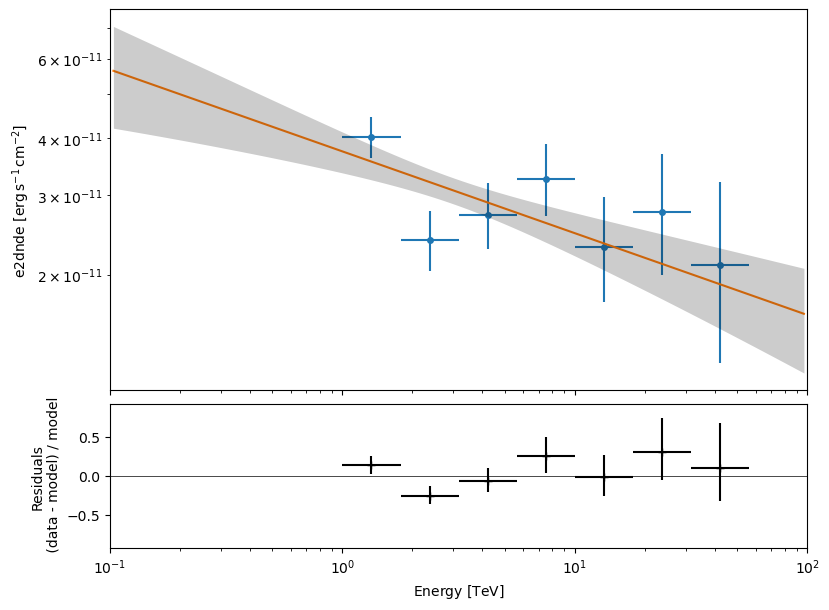

In [109]:
flux_points_dataset_joint = FluxPointsDataset(
    data=flux_points_basil_joint, models=datasets_basil.models
)
ax, _ = flux_points_dataset_joint.plot_fit()

# Dataset creation - stacked analysis

In [110]:
# Create stacked list of zeta-BDT values

file_path_stacked = project_folder+'/stacked/'

# Compute likelihood lists
energy_axis = datasets_basil[0].counts.geom.axes["energy"]
energy = energy_axis.center.value
for i in range(len(datasets_basil)):
    run = datasets_basil[i].name
    
    ### Change if necessary ###
    file_path = project_folder+'/run{:}'.format(run)+'/basil_factors'
    ###########################

    like_gamma_list = []
    like_bkg_list = []
    for j in range(len(energy)):
        like_gamma_list.append([])
        like_bkg_list.append([])
        
        with open(file_path+'/likelihoods/likelihood_gamma_bin'+str(energy[j])+'.pkl', 'rb') as file:
            like_gamma = pickle.load(file)

        with open(file_path+'/likelihoods/likelihood_bkg_bin'+str(energy[j])+'.pkl', 'rb') as file:
            like_bkg = pickle.load(file)
        
        if len(like_gamma) > 0:
            for k in range(len(like_gamma)):
                like_gamma_list[j].append(like_gamma[k])
                like_bkg_list[j].append(like_bkg[k])

    # Save likelihood list
    with open(file_path+'/likelihoods/likelihood_gamma_list_run'+str(run)+'.pkl', 'wb') as h:
        pickle.dump(like_gamma_list, h, pickle.HIGHEST_PROTOCOL)
    with open(file_path+'/likelihoods/likelihood_bkg_list_run'+str(run)+'.pkl', 'wb') as h:
        pickle.dump(like_bkg_list, h, pickle.HIGHEST_PROTOCOL)

        
### Stack likelihoods 
# Initialization with first run
run = datasets_basil[0].name
### Change if necessary ###
file_path = project_folder+'/run{:}'.format(run)+'/basil_factors'
###########################
with open(file_path+'/likelihoods/likelihood_gamma_list_run'+str(run)+'.pkl', 'rb') as file:
    like_gamma_list = pickle.load(file)
with open(file_path+'/likelihoods/likelihood_bkg_list_run'+str(run)+'.pkl', 'rb') as file:
    like_bkg_list = pickle.load(file)
    
# Apply energy threshold mask    
i = 0
while datasets_basil[0].mask_safe.data[i][0][0] == False:
    like_gamma_list[i] = []
    like_bkg_list[i] = []
    i += 1    
    
# Append other runs
for i in range(1,len(datasets_basil)):
    run = datasets_basil[i].name
    ### Change if necessary ###
    file_path = project_folder+'/run{:}'.format(run)+'/basil_factors'
    ###########################
    with open(file_path+'/likelihoods/likelihood_gamma_list_run'+str(run)+'.pkl', 'rb') as file:
        res = pickle.load(file)
    with open(file_path+'/likelihoods/likelihood_bkg_list_run'+str(run)+'.pkl', 'rb') as file:
        res_bkg = pickle.load(file)
    # Apply energy threshold mask 
    k = 0
    while datasets_basil[i].mask_safe.data[k][0][0] == False:
        res[k] = []
        res_bkg[k] = []
        k += 1
    for j in range(len(res)):
        if len(like_gamma_list[j]) == 0:
            if len(res[j]) > 0:
                like_gamma_list[j] = res[j]
                like_bkg_list[j] = res_bkg[j]
        else: # there is data in res_stack
            if len(res[j]) > 0:
                like_gamma_list[j] = np.append(like_gamma_list[j], res[j])
                like_bkg_list[j] = np.append(like_bkg_list[j], res_bkg[j])

# Save res
with open(file_path_stacked+'/likelihood_gamma_list_stacked.pkl', 'wb') as h:
    pickle.dump(like_gamma_list, h, pickle.HIGHEST_PROTOCOL)
with open(file_path_stacked+'/likelihood_bkg_list_stacked.pkl', 'wb') as h:
    pickle.dump(like_bkg_list, h, pickle.HIGHEST_PROTOCOL)
#---------------

    
# # Append other runs
# for i in range(1,len(obs_ids)):
#     with open('./Sources/Crab/theta2_psf/'+str(obs_ids[i])+'/likelihood_bkg_list_run'+str(obs_ids[i])+'_new.pkl', 'rb') as file:
#         res = pickle.load(file)
#     # Apply energy threshold mask 
#     k = 0
#     while datasets_basil[i].mask_safe.data[k][0][0] == False:
#         res[k] = []
#         k += 1
#     for j in range(len(res)):
#         if len(like_bkg_list[j]) == 0:
#             if len(res[j]) > 0:
#                 like_bkg_list[j] = res[j]
#         else: # there is data in res_stack
#             if len(res[j]) > 0:
#                 like_bkg_list[j] = np.append(like_bkg_list[j], res[j])

# # Save res
# with open('./Sources/Crab/theta2_psf/likelihood_bkg_list_stacked.pkl', 'wb') as h:
#     pickle.dump(like_bkg_list, h, pickle.HIGHEST_PROTOCOL)
    





#-------------
# Compute factors - Stacked analysis
basil_class = basil_factors(n_on=stacked.counts.data, n_off=stacked.counts_off.data, alpha=stacked.alpha.data, energy=energy_axis.center.value)
basil_class.run(like_gamma_list, like_bkg_list,file_path_stacked)

In [ ]:
# Create stacked list of zeta-BDT values
obs_ids = [23523, 23526, 23559, 23592]


# Compute likelihood lists
energy_axis = datasets_basil[0].counts.geom.axes["energy"]
energy_ = energy_axis.center.value
for i in range(len(datasets_basil)):
    dataset = datasets_basil[i]
    run = obs_ids[i]
    label= 'crab/theta2_psf/'+str(run)

    like_gamma_list = []
    like_bkg_list = []
    for j in range(len(energy_)):
        like_gamma_list.append([])
        like_bkg_list.append([])
        
        with open('/home/matheus/Documents/BASiL/dist/factors/'+label+'/likelihoods/likelihood_gamma_bin'+str(energy_[j])+'.pkl', 'rb') as file:
            like_gamma = pickle.load(file)

        with open('/home/matheus/Documents/BASiL/dist/factors/'+label+'/likelihoods/likelihood_bkg_bin'+str(energy_[j])+'.pkl', 'rb') as file:
            like_bkg = pickle.load(file)
        
        if len(like_gamma) > 0:
            for k in range(len(like_gamma)):
                like_gamma_list[j].append(like_gamma[k])
                like_bkg_list[j].append(like_bkg[k])

    # Save likelihood list
    with open('./Sources/Crab/theta2_psf/'+str(run)+'/likelihood_gamma_list_run'+str(run)+'_new.pkl', 'wb') as h:
        pickle.dump(like_gamma_list, h, pickle.HIGHEST_PROTOCOL)
    with open('./Sources/Crab/theta2_psf/'+str(run)+'/likelihood_bkg_list_run'+str(run)+'_new.pkl', 'wb') as h:
        pickle.dump(like_bkg_list, h, pickle.HIGHEST_PROTOCOL)

        
# Stack likelihoods (gamma)
# Initialization with first run
with open('./Sources/Crab/theta2_psf/'+str(obs_ids[0])+'/likelihood_gamma_list_run'+str(obs_ids[0])+'_new.pkl', 'rb') as file:
    like_gamma_list = pickle.load(file)

# Apply energy threshold mask    
i = 0
while datasets_basil[0].mask_safe.data[i][0][0] == False:
    like_gamma_list[i] = []
    i += 1    
    
# Append other runs
for i in range(1,len(obs_ids)):
    with open('./Sources/Crab/theta2_psf/'+str(obs_ids[i])+'/likelihood_gamma_list_run'+str(obs_ids[i])+'_new.pkl', 'rb') as file:
        res = pickle.load(file)
    # Apply energy threshold mask 
    k = 0
    while datasets_basil[i].mask_safe.data[k][0][0] == False:
        res[k] = []
        k += 1
    for j in range(len(res)):
        if len(like_gamma_list[j]) == 0:
            if len(res[j]) > 0:
                like_gamma_list[j] = res[j]
        else: # there is data in res_stack
            if len(res[j]) > 0:
                like_gamma_list[j] = np.append(like_gamma_list[j], res[j])

# Save res
with open('./Sources/Crab/theta2_psf/likelihood_gamma_list_stacked.pkl', 'wb') as h:
    pickle.dump(like_gamma_list, h, pickle.HIGHEST_PROTOCOL)
    
    
# Stack likelihoods (background)
# Initialization with first run
with open('./Sources/Crab/theta2_psf/'+str(obs_ids[0])+'/likelihood_bkg_list_run'+str(obs_ids[0])+'_new.pkl', 'rb') as file:
    like_bkg_list = pickle.load(file)

# Apply energy threshold mask    
i = 0
while datasets_basil[0].mask_safe.data[i][0][0] == False:
    like_bkg_list[i] = []
    i += 1    
    
# Append other runs
for i in range(1,len(obs_ids)):
    with open('./Sources/Crab/theta2_psf/'+str(obs_ids[i])+'/likelihood_bkg_list_run'+str(obs_ids[i])+'_new.pkl', 'rb') as file:
        res = pickle.load(file)
    # Apply energy threshold mask 
    k = 0
    while datasets_basil[i].mask_safe.data[k][0][0] == False:
        res[k] = []
        k += 1
    for j in range(len(res)):
        if len(like_bkg_list[j]) == 0:
            if len(res[j]) > 0:
                like_bkg_list[j] = res[j]
        else: # there is data in res_stack
            if len(res[j]) > 0:
                like_bkg_list[j] = np.append(like_bkg_list[j], res[j])

# Save res
with open('./Sources/Crab/theta2_psf/likelihood_bkg_list_stacked.pkl', 'wb') as h:
    pickle.dump(like_bkg_list, h, pickle.HIGHEST_PROTOCOL)
    
# Compute factors - Stacked analysis
energy_axis = stacked_prebasil.counts.geom.axes["energy"]
    
basil_class = basil_factors(n_on=stacked_prebasil.counts.data, n_off=stacked_prebasil.counts_off.data, alpha=stacked_prebasil.alpha.data, energy=energy_axis.center.value)

label_likelihood = '/home/matheus/Documents/BASiL/Sources/Crab/theta2_psf'

with open(label_likelihood+'/likelihood_gamma_list_stacked.pkl', 'rb') as file:
    like_sig = pickle.load(file)
with open(label_likelihood+'/likelihood_bkg_list_stacked.pkl', 'rb') as file:
    like_bkg = pickle.load(file)
        
label_factors = 'crab/theta2_psf'
basil_class.run_stacked(label_factors, like_sig, like_bkg)

In [111]:
# Stacked Analysis
stacked_basil = SpectrumDatasetOnOffBASiL(name='stacked')
# Include information from standard dataset
stacked_basil.counts = stacked.counts
stacked_basil.counts_off = stacked.counts_off  
stacked_basil.exposure = stacked.exposure
stacked_basil.acceptance = stacked.acceptance
stacked_basil.acceptance_off = stacked.acceptance_off
stacked_basil.gti = stacked.gti
stacked_basil.mask_fit = stacked.mask_fit
stacked_basil.psf = stacked.psf
stacked_basil.edisp = stacked.edisp
stacked_basil.mask_safe = stacked.mask_safe
stacked_basil.meta_table = stacked.meta_table


dict_logprod = {}
for j in range(len(energy)):
    with open(file_path_stacked+'/prod_bin'+str(energy[j])+'.pkl', 'rb') as file:
        logprod = pickle.load(file)
    dict_logprod[str(energy[j])] = logprod

stacked_basil.dict_logprod = dict_logprod


# Significance 

# Model fit

## Joint

In [165]:
model = PowerLawSpectralModel(
    index=2.2,
    amplitude="1e-11 cm-2 s-1 TeV-1",
    reference="1 TeV",
)

crab_model_1_b = SkyModel(spectral_model=model,
                    name="crab_model")

datasets_basil.models = [crab_model_1_b]

fit = Fit()
result_fit_joint = fit.run(datasets=datasets_basil)

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.



In [166]:
result_fit_joint.parameters.to_table()

type,name,value,unit,error,min,max,frozen,link,prior
str1,str9,float64,str14,float64,float64,float64,bool,str1,str1
,index,2.1808e+00,,7.254e-02,nan,nan,False,,
,amplitude,2.3356e-11,TeV-1 s-1 cm-2,2.421e-12,nan,nan,False,,
,reference,1.0000e+00,TeV,0.000e+00,nan,nan,True,,


## Stacked

In [167]:
model =  PowerLawSpectralModel(
    index=2.2,
    amplitude="1e-11 cm-2 s-1 TeV-1",
    reference="1 TeV",
)

crab_model_1_b = SkyModel(spectral_model=model,
                    name="crab_model_stacked")

stacked_basil.models = [crab_model_1_b]

fit = Fit()
result_fit_stacked = fit.run(datasets=stacked_basil)

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.



In [168]:
result_fit_stacked.parameters.to_table()

type,name,value,unit,error,min,max,frozen,link,prior
str1,str9,float64,str14,float64,float64,float64,bool,str1,str1
,index,2.1800e+00,,7.282e-02,nan,nan,False,,
,amplitude,2.3126e-11,TeV-1 s-1 cm-2,2.411e-12,nan,nan,False,,
,reference,1.0000e+00,TeV,0.000e+00,nan,nan,True,,


In [169]:
e_reco = np.logspace(-1, 2, 13) * u.TeV 

fpe = FluxPointsEstimator(
    energy_edges=e_reco, source="crab_model_stacked", selection_optional="all",
)
flux_points_basil_stacked = fpe.run(datasets=stacked_basil)


It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.



# Spectrum

In [172]:
e_reco = np.logspace(-1, 2, 13) * u.TeV 

fpe = FluxPointsEstimator(
    energy_edges=e_reco, source="crab_model", selection_optional="all",
)
flux_points_basil_joint = fpe.run(datasets=datasets_basil)

fpe = FluxPointsEstimator(
    energy_edges=e_reco, source="crab_model_stacked", selection_optional="all",
)

flux_points_dataset_stacked = FluxPointsDataset(
    data=flux_points_basil_stacked, models=stacked_basil.models
)

flux_points_basil_stacked = fpe.run(datasets=stacked_basil)


It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.



/home/matheus/miniconda3/envs/gammapy-1.3-test/lib/python3.11/site-packages/gammapy/datasets/core.py:240: RuntimeWarning: overflow encountered in scalar add
  stat_sum += dataset.stat_sum()
/home/matheus/miniconda3/envs/gammapy-1.3-test/lib/python3.11/site-packages/gammapy/datasets/core.py:240: RuntimeWarning: overflow encountered in scalar add
  stat_sum += dataset.stat_sum()
/home/matheus/miniconda3/envs/gammapy-1.3-test/lib/python3.11/site-packages/gammapy/datasets/core.py:240: RuntimeWarning: overflow encountered in scalar add
  stat_sum += dataset.stat_sum()
/home/matheus/miniconda3/envs/gammapy-1.3-test/lib/python3.11/site-packages/gammapy/datasets/core.py:240: RuntimeWarning: overflow encountered in scalar add
  stat_sum += dataset.stat_sum()
/home/matheus/miniconda3/envs/gammapy-1.3-test/lib/python3.11/site-packages/gammapy/datasets/core.py:240: RuntimeWarning: overflow encountered in scalar add
  stat_sum += dataset.stat_sum()


It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.

It is using BASiL.



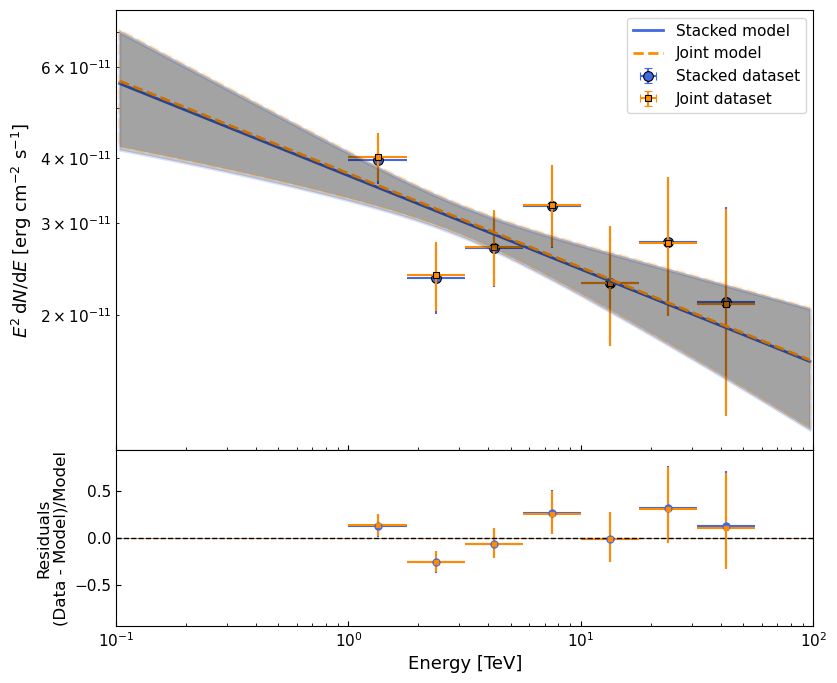

<Figure size 900x700 with 0 Axes>

In [171]:
### Plotting the spectra

# First dataset: stacked
kwargs_spectrum_stacked = {
    "kwargs_fp": {
        "color": "royalblue",
        "marker": "o",
        "markersize": 7,
        "markeredgecolor": "black",
        "markeredgewidth": 0.8,
        "ls": "none",
        "label": "Stacked dataset",
        "zorder": 5,
    },
    "kwargs_model": {
    "color": "royalblue",
    "ls": "-",
    "linewidth": 2,
    "label": "Stacked model",
    }
}

kwargs_residuals_stacked = {
    "color": "royalblue",
    "marker": "o",
    "markersize": 5,
    "ls": "none",
}

# Second dataset: joint
kwargs_spectrum_joint = {
    "kwargs_fp": {
        "color": "darkorange",
        "marker": "s",
        "markersize": 5,
        "markeredgecolor": "black",
        "markeredgewidth": 0.8,
        "ls": "none",
        "label": "Joint dataset",
        "zorder": 6,
    },
    "kwargs_model": {
        "color": "darkorange",
        "ls": "--",
        "linewidth": 2,
        "label": "Joint model",
    },
}

kwargs_residuals_joint = {
    "color": "darkorange",
    "marker": "s",
    "markersize": 3,
    "ls": "none",
}



# Plot stacked dataset
ax_spectrum, ax_residuals = flux_points_dataset_stacked.plot_fit(
    kwargs_spectrum=kwargs_spectrum_stacked,
    kwargs_residuals=kwargs_residuals_stacked,
)

flux_points_dataset_joint.plot_fit(
    ax_spectrum=ax_spectrum, ax_residuals=ax_residuals,
    kwargs_spectrum=kwargs_spectrum_joint,
    kwargs_residuals=kwargs_residuals_joint,
)

ax_spectrum.set_xlabel("Energy [TeV]", fontsize=13)
ax_spectrum.set_ylabel(
    r"$E^2\,{\rm d}N/{\rm d}E$ [erg cm$^{-2}$ s$^{-1}$]",
    fontsize=13,
)

ax_spectrum.tick_params(
    axis="both", which="both", direction="in",
    top=False, right=False, labelsize=11
)

ax_spectrum.legend(
    fontsize=11,
    loc="best",
)

# Residual panel
ax_residuals.axhline(
    0, color="black", linestyle="--", lw=1
)

ax_residuals.set_xlabel("Energy [TeV]", fontsize=13)
ax_residuals.set_ylabel("Residuals"+"\n"+"(Data - Model)/Model", fontsize=12)

ax_residuals.tick_params(
    axis="both", which="both", direction="in",
    top=False, right=False, labelsize=11
)


fig = ax_spectrum.figure
fig.set_size_inches(9, 8)

fig.subplots_adjust(hspace=0)

